# 13 — Direct collocation

**Objectives.** Construct Radau collocation coefficients, enforce dynamics at polynomial nodes, and compare the resulting structure with shooting. On each interval, a degree-$d$ polynomial approximates the state. Its derivative equals the ODE at collocation nodes; an interpolation equation connects interval endpoints. This gives high accuracy without numerically integrating inside every NLP evaluation.


In [1]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

### Derive Radau collocation coefficients

`ca.collocation_points` supplies normalized Radau nodes. The cell builds
one Lagrange basis polynomial for each node, differentiates and integrates
those polynomials with NumPy, and stores the coefficients needed by the
direct-collocation transcription.

For nodes $\tau_0,\ldots,\tau_d$, the $j$-th basis polynomial is

$$
L_j(\tau)=\prod_{r\ne j}
\frac{\tau-\tau_r}{\tau_j-\tau_r}.
$$

The three coefficient families are

$$
C_{jr}=\dot L_j(\tau_r),\qquad
D_j=L_j(1),\qquad
B_j=\int_0^1L_j(\tau)\,d\tau.
$$

The quadrature weights must sum to one because the rule integrates a
constant exactly: $\sum_jB_j=1$.


In [2]:
import casadi as ca
import numpy as np

polynomial_degree = 3

# collocation_points returns normalized nodes for the selected scheme.
collocation_nodes = [0.0] + ca.collocation_points(
    polynomial_degree,
    "radau",
)
derivative_coefficients = np.zeros((polynomial_degree + 1, polynomial_degree + 1))
endpoint_coefficients = np.zeros(polynomial_degree + 1)
quadrature_weights = np.zeros(polynomial_degree + 1)

# Build the Lagrange basis polynomial associated with every node.
for basis_index in range(polynomial_degree + 1):
    basis_polynomial = np.poly1d([1.0])
    for node_index in range(polynomial_degree + 1):
        if node_index == basis_index:
            continue
        basis_polynomial *= np.poly1d([1.0, -collocation_nodes[node_index]]) / (
            collocation_nodes[basis_index] - collocation_nodes[node_index]
        )

    endpoint_coefficients[basis_index] = basis_polynomial(1.0)
    basis_derivative = np.polyder(basis_polynomial)
    for node_index in range(polynomial_degree + 1):
        derivative_coefficients[basis_index, node_index] = basis_derivative(
            collocation_nodes[node_index]
        )
    quadrature_weights[basis_index] = np.polyint(basis_polynomial)(1.0)

print(
    "nodes:",
    collocation_nodes,
    "quadrature weights:",
    quadrature_weights,
    "weight sum:",
    quadrature_weights.sum(),
)
np.testing.assert_allclose(quadrature_weights.sum(), 1.0)

nodes: [0.0, 0.15505102572168222, 0.6449489742783179, 1.0] quadrature weights: [-8.88178420e-16  3.76403063e-01  5.12485826e-01  1.11111111e-01] weight sum: 1.0


### Build the direct-collocation optimal-control transcription

The cell creates mesh states, interval controls, and internal collocation
states with `Opti.variable`. At each Radau point it equates the derivative
of the interpolating polynomial with the model dynamics. The previously
computed quadrature weights approximate the running cost, and the
endpoint coefficients connect each interval to the next mesh state.

For $\dot x=-x+u$, the collocation equations are

$$
\sum_{r=0}^{d}C_{rj}x_{k,r}
=h\left(-x_{k,j}+u_k\right),\qquad j=1,\ldots,d,
$$

and the interval endpoint is

$$
x_{k+1}=\sum_{r=0}^{d}D_rx_{k,r}.
$$

The discretized objective is

$$
\sum_{k=0}^{N-1}\sum_{j=1}^{d}
hB_j\left(x_{k,j}^2+0.1u_k^2\right)+x_N^2.
$$

The resulting figure plots the optimized mesh state $x_k$ and piecewise-constant manipulated input $u_k$ over the complete horizon.



******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

terminal x: 0.016638032004762254 running cost: 0.23258116106186638


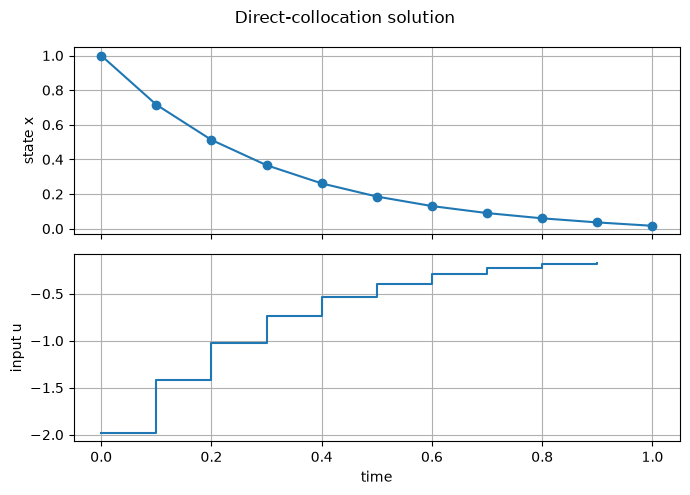

In [3]:
import matplotlib.pyplot as plt

number_of_intervals = 10
step_size = 0.1
optimization = ca.Opti()
x_mesh = [optimization.variable()]
u_intervals = []
running_cost = 0
optimization.subject_to(x_mesh[0] == 1.0)

for interval_index in range(number_of_intervals):
    u = optimization.variable()
    u_intervals.append(u)
    x_collocation = [x_mesh[-1]] + [optimization.variable() for _ in range(polynomial_degree)]

    # Match the polynomial derivative to x_dot = -x + u at each node.
    for node_index in range(1, polynomial_degree + 1):
        polynomial_derivative = sum(
            derivative_coefficients[basis_index, node_index] * x_collocation[basis_index]
            for basis_index in range(polynomial_degree + 1)
        )
        optimization.subject_to(
            polynomial_derivative == step_size * (-x_collocation[node_index] + u)
        )
        running_cost += (
            step_size
            * quadrature_weights[node_index]
            * (x_collocation[node_index] ** 2 + 0.1 * u**2)
        )

    x_interval_end = sum(
        endpoint_coefficients[basis_index] * x_collocation[basis_index]
        for basis_index in range(polynomial_degree + 1)
    )
    x_next = optimization.variable()
    x_mesh.append(x_next)
    optimization.subject_to(x_next == x_interval_end)

optimization.minimize(running_cost + x_mesh[-1] ** 2)
optimization.solver(
    "ipopt",
    {"print_time": False},
    {"print_level": 0},
)
solution = optimization.solve()
x_solution = np.array([solution.value(value) for value in x_mesh])
u_solution = np.array([solution.value(value) for value in u_intervals])
print(
    "terminal x:",
    x_solution[-1],
    "running cost:",
    solution.value(running_cost),
)
assert abs(x_solution[-1]) < 0.5

x_time = step_size * np.arange(number_of_intervals + 1)
u_time = x_time[:-1]
figure, axes = plt.subplots(2, 1, sharex=True, figsize=(7, 5))
axes[0].plot(x_time, x_solution, marker="o")
axes[0].set_ylabel("state x")
axes[0].grid(True)
axes[1].step(u_time, u_solution, where="post")
axes[1].set(xlabel="time", ylabel="input u")
axes[1].grid(True)
figure.suptitle("Direct-collocation solution")
figure.tight_layout()
plt.show()

Path constraints should be enforced at enough points to control between-node violations. For free final time, normalize time to $[0,1]$ and multiply the dynamics/cost by the duration decision.

**Common mistakes:** transposing `C`, forgetting the interval length in dynamics/quadrature, and comparing meshes without checking constraint violation between nodes. **Recap:** collocation turns differential equations into sparse algebraic residuals.
